> **Versão pública (2026).** Notebook original, executado no Google Colab com GPU. Os dados vêm da API do Kaggle (competição Titanic), com a chave de quem executa, e cada treino também era salvo num bucket do Google Cloud Storage. A chave, as credenciais, o projeto e o bucket (`<PROJETO_GCP>` e `<BUCKET_GCS>`) não fazem parte do repositório. As saídas são as originais. Veja o [README desta pasta](README.md).

### OBS: Fazer upload arquivo de chave da API do kaggle (kaggle.json)

In [1]:
%%sh
rm -r sample_data

In [2]:
%%sh
pip install -q kaggle

In [3]:
%%sh
mkdir ~/.kaggle

In [4]:
%%sh
cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
kaggle competitions download -c titanic && unzip -o titanic.zip && rm titanic.zip


Archive:  titanic.zip
  inflating: gender_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


100%|██████████| 34.1k/34.1k [00:00<00:00, 3.76MB/s]


In [5]:
from subprocess import run

import numpy as np
import pandas as pd

import tensorflow as tf
import cvxpy as cp
import zipfile
import os

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output

import json
from google.cloud import storage
from google.oauth2 import service_account
from tqdm import tqdm


import time

In [6]:
def informacoes_maquina():
    data = run('lscpu', capture_output = True, shell = True)
    output = data.stdout.splitlines()
    dict_cpu = {}
    for line in output:
        line = line.decode('utf-8')
        chave = line.split(':')[0].strip()
        valor = line.split(':')[1].strip()
        dict_cpu[chave] = valor
    series_cpu = pd.Series(dict_cpu)
    series_cpu = series_cpu[['CPU(s)']]

    data = run('cat /proc/meminfo', capture_output = True, shell = True)
    output = data.stdout.splitlines()
    dict_memoria = {}
    for line in output:
        line = line.decode('utf-8')
        chave = line.split(':')[0].strip()
        valor = line.split(':')[1].strip()
        dict_memoria[chave] = valor
    series_memoria = pd.Series(dict_memoria)
    series_memoria = series_memoria[['MemTotal']]

    display(pd.DataFrame(pd.concat([series_cpu, series_memoria]), columns = ['Informação']))

    data = run('nvidia-smi', capture_output = True, shell = True)
    output = data.stdout.decode('utf-8')
    print('')
    print(50*'=')
    print('GPU:')
    print(output)

In [7]:
informacoes_maquina()

Informação
CPU(s)              8
MemTotal  53470708 kB


GPU:
Thu Jan 23 20:01:05 2025       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla T4                       Off | 00000000:00:04.0 Off |                    0 |
| N/A   56C    P8              12W /  70W |      0MiB / 15360MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+-------------------

# Fazer o upload das credenciais do Google Cloud Storage

In [8]:
with open('credentials.json') as source:
    credenciais = json.load(source)

storage_credentials = service_account.Credentials.from_service_account_info(credenciais)
storage_client = storage.Client(project = '<PROJETO_GCP>', credentials = storage_credentials)

bucket = storage_client.bucket('<BUCKET_GCS>')

# Preparação dos dados

In [9]:
df_tot = pd.read_csv('train.csv', dtype = {'Survived': str, 'Pclass': str})

In [10]:
df_tot['Titulo'] = df_tot['Name'].apply(lambda x: x.split(',')[1].split('.')[0].strip())
df_tot['Tem_Age'] = (~df_tot['Age'].isna()).astype(int)

colunas_ohe = ['Pclass', 'Sex', 'Titulo', 'Embarked']
dict_ohe = {}
for c in colunas_ohe:
    series_count = df_tot[c].value_counts()
    series_count = series_count[series_count >= 40]
    dict_ohe[c] = list(series_count.index)
    for v in dict_ohe[c]:
        df_tot[f'{c}_{v}'] = (df_tot[c] == v).astype(int)
    df_tot = df_tot.drop(c, axis = 1)

features = [
    'Age'
    ,'SibSp'
    ,'Parch'
    ,'Fare'
    ,'Tem_Age'
    ,'Pclass_3'
    ,'Pclass_1'
    ,'Pclass_2'
    ,'Sex_male'
    ,'Sex_female'
    ,'Titulo_Mr'
    ,'Titulo_Miss'
    ,'Titulo_Mrs'
    ,'Titulo_Master'
    ,'Embarked_S'
    ,'Embarked_C'
    ,'Embarked_Q']

In [11]:
alvo_categorico = 'Survived'
series_count = df_tot[alvo_categorico].value_counts()
for v in series_count.index:
    df_tot[f'{alvo_categorico}_{v}'] = (df_tot[alvo_categorico] == v).astype(int)
df_tot = df_tot.drop(alvo_categorico, axis = 1)
alvos = ['Survived_0', 'Survived_1']

# Separa conjuntos de treino/teste

In [12]:
N = 300
df = df_tot.iloc[:-N, :].copy()
df_teste = df_tot.iloc[-N:, :].copy()

df_id = df[['PassengerId']].copy()
df_id_teste = df_teste[['PassengerId']].copy()

# Normalização dos dados

In [13]:
medias = np.nanmean(df[features].values, axis = 0)
desvios = np.nanstd(df[features].values, axis = 0)

x = (df[features].values - medias)/desvios
x[np.where(np.isnan(x))] = 0
y = df[alvos].values

if df_teste.shape[0] > 0:
    x_teste = (df_teste[features].values - medias)/desvios
    x_teste[np.where(np.isnan(x_teste))] = 0
    y_teste = df_teste[alvos].values
else:
    x_teste = None
    y_teste = None

In [14]:
desvios

array([14.49239087,  1.10284632,  0.77460665, 46.49513269,  0.40596445,
        0.49750221,  0.42827187,  0.40596445,  0.48340464,  0.48340464,
        0.49551283,  0.41761018,  0.34918545,  0.20880166,  0.45106315,
        0.39457007,  0.28572063])

# Separação dos conjuntos para treinamento

In [15]:
def separa_conjuntos(df_id, num_div):
    df_conj = df_id.copy()
    df_conj['conjunto'] = df_id.index % num_div
    df_conj_count = df_conj[['conjunto', 'PassengerId']].groupby('conjunto').agg(['count', 'nunique']).sort_index()
    display(df_conj_count)
    return df_conj

df_conj = separa_conjuntos(df_id, num_div = 6)
if df_teste.shape[0] > 0:
    df_conj_teste = separa_conjuntos(df_id_teste, num_div = 3)
else:
    df_conj_teste = None

PassengerId        
               count nunique
conjunto                    
0                 99      99
1                 99      99
2                 99      99
3                 98      98
4                 98      98
5                 98      98

PassengerId        
               count nunique
conjunto                    
0                100     100
1                100     100
2                100     100

# Funções para operar redes neurais

In [16]:
def cria_arquitetura_rede_neural_clf(x_shape, y_shape, nome, seed = None):
    seed_temp = seed if seed is not None else None
    camada_entrada = tf.keras.layers.Input(shape = x_shape, name = f'{nome}_entrada')
    lista_camadas = [camada_entrada]

    lista_neuronios = [16, 8, 4, 2]
    for i in range(0, len(lista_neuronios)):
        n = lista_neuronios[i]
        lista_camadas.append(tf.keras.layers.Dense(n,
                                                   activation = 'tanh',
                                                   kernel_initializer = tf.keras.initializers.GlorotUniform(seed_temp), #'glorot_uniform',
                                                   bias_initializer = 'zeros',
                                                   name = f'{nome}_dense{str(i)}')(lista_camadas[-1]))
        seed_temp = seed_temp + 1 if seed is not None else None

    camada_saida = tf.keras.layers.Dense(y_shape,
                                         kernel_initializer = tf.keras.initializers.GlorotUniform(seed_temp), #'glorot_uniform',
                                         bias_initializer = 'zeros',
                                         activation = 'softmax',
                                         name = f'{nome}_saida')(lista_camadas[-1])
    seed_temp = seed_temp + 1 if seed is not None else None

    modelo = tf.keras.models.Model(inputs = camada_entrada, outputs = camada_saida, name = f'{nome}_model')
    return modelo

x_shape = desvios.shape
y_shape = y.shape[1]
cria_arquitetura_rede_neural_clf(x_shape, y_shape, 'arqclf').summary()

Model: "arqclf_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ arqclf_entrada (InputLayer)          │ (None, 17)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ arqclf_dense0 (Dense)                │ (None, 16)                  │             288 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ arqclf_dense1 (Dense)                │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ arqclf_dense2 (Dense)                │ (None, 4)                   │              36 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ arqclf_dense3 (Dense)                │ (None, 2)                   │              10 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ arqclf_saida (Dense)                 │ (None, 2)                   │               6 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 476 (1.86 KB)

 Trainable params: 476 (1.86 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
def cria_arquitetura_rede_neural_rgs(x_shape, y_shape, nome, seed = None):
    seed_temp = seed if seed is not None else None
    camada_entrada = tf.keras.layers.Input(shape = x_shape, name = f'{nome}_entrada')
    lista_camadas = [camada_entrada]

    lista_neuronios = [16, 8, 4, 2]
    for i in range(0, len(lista_neuronios)):
        n = lista_neuronios[i]
        lista_camadas.append(tf.keras.layers.Dense(n,
                                                   activation = 'tanh',
                                                   kernel_initializer = tf.keras.initializers.GlorotUniform(seed_temp), #'glorot_uniform',
                                                   bias_initializer = 'zeros',
                                                   name = f'{nome}_dense{str(i)}')(lista_camadas[-1]))
        seed_temp = seed_temp + 1 if seed is not None else None

    camada_saida = tf.keras.layers.Dense(y_shape,
                                         kernel_initializer = tf.keras.initializers.GlorotUniform(seed_temp), #'glorot_uniform',
                                         bias_initializer = 'zeros',
                                         activation = 'linear',
                                         name = f'{nome}_saida')(lista_camadas[-1])
    seed_temp = seed_temp + 1 if seed is not None else None

    modelo = tf.keras.models.Model(inputs = camada_entrada, outputs = camada_saida, name = f'{nome}_model')
    return modelo

x_shape = desvios.shape
y_shape = 1
cria_arquitetura_rede_neural_clf(x_shape, y_shape, 'arqrgs').summary()

Model: "arqrgs_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ arqrgs_entrada (InputLayer)          │ (None, 17)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ arqrgs_dense0 (Dense)                │ (None, 16)                  │             288 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ arqrgs_dense1 (Dense)                │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ arqrgs_dense2 (Dense)                │ (None, 4)                   │              36 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ arqrgs_dense3 (Dense)                │ (None, 2)                   │              10 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ arqrgs_saida (Dense)                 │ (None, 1)                   │               3 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 473 (1.85 KB)

 Trainable params: 473 (1.85 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
def plot_vies_variancia(df_loss_hist, df_n2gloss_hist, df_epocas_hist,
                        df_loss_hist_teste = None, df_n2gloss_hist_teste = None, df_epocas_hist_teste = None,
                        figsize = [18, 6]):

    paleta_cores = sns.color_palette("colorblind")
    with sns.axes_style("whitegrid"):
        if df_loss_hist_teste is None:
            fig, axs = plt.subplots(1, 2, figsize = figsize, sharex = True)

            ax = axs[0]
            ax.axhline(1, color = 'black', lw = 2)
            ax.plot(df_epocas_hist['Epoca'], df_epocas_hist['Loss_Media'], color = paleta_cores[0], lw = 2, alpha = 1.0, label = 'Média')
            for ind, row in df_loss_hist.iterrows():
                ax.plot(np.arange(0, len(row)-1), row.iloc[1:], color = paleta_cores[0], lw = 1, alpha = 0.5)
            ax.set_ylabel('Loss Normalizada')
            ax.set_xlabel('Época')
            ax.legend(loc = 'upper left')

            ax = axs[1]
            ax.plot(df_epocas_hist['Epoca'], df_epocas_hist['N2GLoss_Media'], color = paleta_cores[0], lw = 2, alpha = 1.0, label = 'Média')
            for ind, row in df_n2gloss_hist.iterrows():
                ax.plot(np.arange(0, len(row)-1), row.iloc[1:], color = paleta_cores[0], lw = 1, alpha = 0.5)
            ax.set_ylabel('N2GLoss Normalizada')
            ax.set_xlabel('Época')
            ax.legend(loc = 'upper left')
        else:
            fig, axs = plt.subplots(2, 2, figsize = [figsize[0], int(round(1.5*figsize[1]))], sharex = True)

            ax = axs[0][0]
            ax.axhline(1, color = 'black', lw = 2)
            ax.plot(df_epocas_hist['Epoca'], df_epocas_hist['Loss_Media'], color = paleta_cores[0], lw = 2, alpha = 1.0, label = 'Média')
            for ind, row in df_loss_hist.iterrows():
                ax.plot(np.arange(0, len(row)-1), row.iloc[1:], color = paleta_cores[0], lw = 1, alpha = 0.5)
            ax.set_ylabel('Loss Normalizada')
            ax.set_xlabel('Época')
            ax.legend(loc = 'upper left')

            ax = axs[0][1]
            ax.plot(df_epocas_hist['Epoca'], df_epocas_hist['N2GLoss_Media'], color = paleta_cores[0], lw = 2, alpha = 1.0, label = 'Média')
            for ind, row in df_n2gloss_hist.iterrows():
                ax.plot(np.arange(0, len(row)-1), row.iloc[1:], color = paleta_cores[0], lw = 1, alpha = 0.5)
            ax.set_ylabel('N2GLoss Normalizada')
            ax.set_xlabel('Época')
            ax.legend(loc = 'upper left')

            ax = axs[1][0]
            ax.axhline(1, color = 'black', lw = 2)
            ax.plot(df_epocas_hist_teste['Epoca'], df_epocas_hist_teste['Loss_Media'], color = paleta_cores[1], lw = 2, alpha = 1.0, label = 'Média')
            for ind, row in df_loss_hist_teste.iterrows():
                ax.plot(np.arange(0, len(row)-1), row.iloc[1:], color = paleta_cores[1], lw = 1, alpha = 0.5)
            ax.set_ylabel('Loss Normalizada (Teste)')
            ax.set_xlabel('Época')
            ax.legend(loc = 'upper left')

            ax = axs[1][1]
            ax.plot(df_epocas_hist_teste['Epoca'], df_epocas_hist_teste['N2GLoss_Media'], color = paleta_cores[1], lw = 2, alpha = 1.0, label = 'Média')
            for ind, row in df_n2gloss_hist_teste.iterrows():
                ax.plot(np.arange(0, len(row)-1), row.iloc[1:], color = paleta_cores[1], lw = 1, alpha = 0.5)
            ax.set_ylabel('N2GLoss Normalizada (Teste)')
            ax.set_xlabel('Época')
            ax.legend(loc = 'upper left')
        plt.show()

In [19]:
def fit_modelo(nome_modelo, df_conj, x, y, tipo = 'classificacao', #Informações dos dados para treinamento
               n_epocas = 100, batch_size = 1024, delta_loss_min = 0.0001, #Configurações que impactam o tempo de treinamento
               delta_loss_init = 0.01 , seed = None, #Informações que impactam o resultado dos treinamentos
               path_local = '', bucket = None, path_gcloud = '', #Informações para salvar o treinamento na núvem
               modelo_ref = None, #Dados para continuar um treinamento que já estava em andamento
               df_epocas_hist_ref = None, df_loss_hist_ref = None, df_n2gloss_hist_ref = None,
               df_conj_teste = None, x_teste = None, y_teste = None, #Informações de dados de teste para acompanhamento, se houver
               df_epocas_hist_teste_ref = None, df_loss_hist_teste_ref = None, df_n2gloss_hist_teste_ref = None):

    #Se for tipo = 'classificacao', o y deve ser o alvo já com One Hot Encoder aplicado
    #Se for tipo = 'regressao', o y deve ser o alvo já com normalização de média 0.0 e desvio padrão 1.0
    #x deve ser as features do modelo já normalizadas e com nulos tratados
    #df_conj é um dataframe de De-Para indicando a qual conjunto de treino pertence cada linha de treinamento
    #OBS: os indices do dataframe df_conj devem ser únicos, caso contrário vai causar problema na separação dos batches
    #batch_size é um parâmetro para tornar treinável tanto em GPUs simples quanto em GPUs robustas
    #delta_loss_init é um parâmetro que regula o passo de aprendizado que o treinamento tentará fazer a cada época (funciona como um learning_rate)
    #delta_loss_min é um parâmetro que avalia se está tendo uma diminuição significa da loss, para saber se compensa continuar treinando

    #Cria a pasta do modelo
    try:
        os.system(f'rm -r {path_local}{nome_modelo}')
    except:
        pass
    try:
        os.mkdir(f'{path_local}{nome_modelo}')
    except:
        pass

    #Agrega todos os conjuntos de treinamento para sabermos quantos conjuntos temos e quantos exemplos temos em cada um deles
    df_conj_agg = df_conj[['conjunto']].reset_index().groupby('conjunto').count().sort_index().reset_index().rename({'index': 'exemplos'}, axis = 1)
    if df_conj_teste is not None:
        df_conj_agg_teste = df_conj_teste[['conjunto']].reset_index().groupby('conjunto').count().sort_index().reset_index().rename({'index': 'exemplos'}, axis = 1)

    #Separa os conjuntos em batches para deixar treinável mesmo em GPUs mais simples
    def separa_batches(df_conj, batch_size = 1024):
        lista_conj_temp = []
        for conj in range(0, df_conj['conjunto'].unique().size):
            df_conj_temp = df_conj[df_conj['conjunto'] == conj].copy()
            df_conj_temp['batch'] = np.arange(0, df_conj_temp.shape[0])
            df_conj_temp['batch'] = df_conj_temp['batch'] // batch_size
            lista_conj_temp.append(df_conj_temp)
        df_conj_batches = pd.concat(lista_conj_temp).sort_index()
        return df_conj_batches
    df_conj_batches = separa_batches(df_conj, batch_size = batch_size)
    if df_conj_teste is not None:
        df_conj_batches_teste = separa_batches(df_conj_teste, batch_size = batch_size)

    #Inicializa a Rede Neural que será treinada (do zero ou carrega a Rede Neural passada como referência)
    if modelo_ref is None:
        x_shape = x.shape[1:]
        if tipo == 'classificacao':
            y_shape = y.shape[1]
            modelo = cria_arquitetura_rede_neural_clf(x_shape, y_shape, nome_modelo, seed)
        else:
            y_shape = 1
            modelo = cria_arquitetura_rede_neural_rgs(x_shape, y_shape, nome_modelo, seed)
        modelo.save(f'{path_local}{nome_modelo}/modelo_inicial.keras')
        df_epocas_hist = pd.DataFrame(columns = ['Epoca', 'Taxa_Aprendizado',
                                                 'Loss_Min', 'Loss_Q1', 'Loss_Q2', 'Loss_Q3', 'Loss_Max',
                                                 'Loss_Desvio', 'Loss_Media',
                                                 'N2GLoss_Min', 'N2GLoss_Q1', 'N2GLoss_Q2', 'N2GLoss_Q3', 'N2GLoss_Max',
                                                 'N2GLoss_Desvio', 'N2GLoss_Media'])
        df_loss_hist = None
        df_n2gloss_hist = None
        epoca_ini = 0
        delta_ideal = 1
        if df_conj_teste is not None:
            df_epocas_hist_teste = df_epocas_hist.copy()
            df_loss_hist_teste = None
            df_n2gloss_hist_teste = None
    else:
        modelo = tf.keras.models.clone_model(modelo_ref)
        modelo.set_weights(modelo_ref.get_weights())
        df_epocas_hist = df_epocas_hist_ref.copy()
        df_loss_hist = df_loss_hist_ref.copy()
        df_n2gloss_hist = df_n2gloss_hist_ref.copy()
        epoca_ini = df_epocas_hist.shape[0]
        delta_ideal = df_epocas_hist.iloc[-1]['Taxa_Aprendizado']
        if df_conj_teste is not None:
            df_epocas_hist_teste = df_epocas_hist_teste_ref.copy()
            df_loss_hist_teste = df_loss_hist_teste_ref.copy()
            df_n2gloss_hist_teste = df_n2gloss_hist_teste_ref.copy()

    #Define a função de perda (loss)
    #Conceitualmente parece que a Entropia Cruzada e o MSE fazem mais sentido por padrão
    #pois o modelo baseline constante é a média para esses dois casos (normalmente é o desejado para um baseline mais geral possível)
    if tipo == 'classificacao':
        func_loss = tf.keras.losses.CategoricalCrossentropy()
        y_ref = y.mean(axis = 0)
    else:
        func_loss = tf.keras.losses.MeanSquaredError()
        y_ref = y.mean()

    #Calcula o valor da loss de referência para cada conjunto (loss do modelo baseline: constante)
    def calcula_metrica_ref_conjunto(df_conj, df_conj_agg, y_ref, y):
        lista_loss_ref = []
        for ind, row in df_conj_agg.iterrows():
            mask_conj = (df_conj['conjunto'] == row['conjunto'])
            y_conj = y[mask_conj]
            if tipo == 'classificacao':
                loss_conj = func_loss(y_conj, np.stack([y_ref]*y_conj.shape[0], axis = 0)).numpy()
            else:
                loss_conj = func_loss(y_conj, np.repeat(y_ref, y_conj.shape[0])).numpy()
            lista_loss_ref.append(loss_conj)
        return lista_loss_ref
    df_conj_agg['loss_ref'] = calcula_metrica_ref_conjunto(df_conj, df_conj_agg, y_ref, y)
    if df_conj_teste is not None:
        df_conj_agg_teste['loss_ref'] = calcula_metrica_ref_conjunto(df_conj_teste, df_conj_agg_teste, y_ref, y_teste)

    #---Funções de apoio para treinamento---

    #Função para ajustar o shape dos pesos para poder atualizá-los no modelo (o algoritmo L-BFGS retorna os pesos flat)
    lista_shape_pesos = [v.shape for v in modelo.get_weights()]
    def ajusta_shape_pesos(pesos_flat):
        i = 0
        pesos = []
        for forma in lista_shape_pesos:
            tam = tf.reduce_prod(forma) #Calcula o número de elementos na forma original
            vetor = pesos_flat[i:i+tam]
            pesos.append(tf.reshape(vetor, forma))
            i += tam
        return pesos

    #Calcula o valor da função de loss e seus gradientes (com retorno flat para ser usado no algoritmo L-BFGS) para um batch
    @tf.function
    def calcula_loss_gradiente_batch(x_batch, y_batch):
        with tf.GradientTape() as tape:
            preds = modelo(x_batch, training = True)
            loss_value = func_loss(y_batch, preds)
            #loss_value += sum(modelo.losses) #Inclui perdas por regularização, caso as layers possuam regularização
        grads = tape.gradient(loss_value, modelo.trainable_variables)
        grads_flat = tf.concat([tf.reshape(k, [-1]) for k in grads], 0)
        return loss_value, grads_flat

    #Calcula o Produto Hessiana*vetor na direção de um vetor dado (dir deve ser um vetor unitário) para um batch
    def calcula_hessiana_direcional_batch(x_batch, y_batch, dir, eps = 1e-4):
        #OBS: Note que, como o tensorflow trabalha com float32 (32 bits), eps não pode ser um valor muito baixo, como 1e-8
        pesos_iniciais = modelo.get_weights()
        pesos_iniciais_flat = tf.concat([tf.reshape(k, [-1]) for k in pesos_iniciais], 0) #peso flat para o L-BFGS
        modelo.set_weights(ajusta_shape_pesos(pesos_iniciais_flat - eps*dir))
        loss_value_inf, grads_flat_inf = calcula_loss_gradiente_batch(x_batch, y_batch)
        modelo.set_weights(ajusta_shape_pesos(pesos_iniciais_flat + eps*dir))
        loss_value_sup, grads_flat_sup = calcula_loss_gradiente_batch(x_batch, y_batch)
        hess_dir_flat = (grads_flat_sup - grads_flat_inf)/(2*eps)
        modelo.set_weights(pesos_iniciais)
        return hess_dir_flat

    #Calcula os pares loss e seu gradiente para todos os conjuntos de treinamento
    def calcula_loss_gradiente(df_conj_batches, df_conj_agg, x, y):
        lista_value_grads_conj = []
        for ind, row in df_conj_agg.iterrows():
            num_batches = df_conj_batches.loc[(df_conj_batches['conjunto'] == row['conjunto']), 'batch'].unique().size
            lista_value_grads_temp = []
            for i in range(0, num_batches):
                mask_batch = (df_conj_batches['conjunto'] == row['conjunto']) & (df_conj_batches['batch'] == i)
                x_batch = x[mask_batch]
                y_batch = y[mask_batch]
                loss_value_batch, grads_batch = calcula_loss_gradiente_batch(x_batch, y_batch)
                qtd_batch = np.sum(mask_batch)
                loss_value_batch = loss_value_batch*qtd_batch
                grads_batch = grads_batch*qtd_batch
                lista_value_grads_temp.append((loss_value_batch, grads_batch))
            loss_value_conj = sum([k[0] for k in lista_value_grads_temp])/row['exemplos']
            grads_conj = sum([k[1] for k in lista_value_grads_temp])/row['exemplos']
            loss_value_conj = loss_value_conj/row['loss_ref']
            grads_conj = grads_conj/row['loss_ref']
            lista_value_grads_conj.append((loss_value_conj, grads_conj))
        loss_conjs = [k[0] for k in lista_value_grads_conj]
        grads_conjs = [k[1] for k in lista_value_grads_conj]
        return loss_conjs, grads_conjs

    #Calcula os pares norma2gradloss e seu gradiente para todos os conjuntos de treinamento
    def calcula_norm2gradloss_gradiente(df_conj_batches, df_conj_agg, x, y):
        loss_conjs, grads_conjs = calcula_loss_gradiente(df_conj_batches, df_conj_agg, x, y)
        lista_hess_grad_conj = []
        for j in range(0, df_conj_agg.shape[0]):
            grad_conj = grads_conjs[j]
            grad_norm_conj = tf.norm(grad_conj)
            grad_dir_conj = grad_conj/grad_norm_conj
            conj = df_conj_agg.iloc[j]['conjunto']
            num_batches = df_conj_batches.loc[(df_conj_batches['conjunto'] == conj), 'batch'].unique().size
            lista_hess_grad_batch = []
            for i in range(0, num_batches):
                mask_batch = (df_conj_batches['conjunto'] == conj) & (df_conj_batches['batch'] == i)
                x_batch = x[mask_batch]
                y_batch = y[mask_batch]
                hess_dir_temp = calcula_hessiana_direcional_batch(x_batch, y_batch, grad_dir_conj, eps = 1e-4)
                qtd_batch = np.sum(mask_batch)
                hess_grad_temp = grad_norm_conj*hess_dir_temp*qtd_batch
                lista_hess_grad_batch.append(hess_grad_temp)
            qtd_exemplos = df_conj_agg.iloc[j]['exemplos']
            hess_grad_conj = sum(lista_hess_grad_batch)/qtd_exemplos
            loss_ref = df_conj_agg.iloc[j]['loss_ref']
            hess_grad_conj = hess_grad_conj/loss_ref
            lista_hess_grad_conj.append(hess_grad_conj)
        norm2gradloss_conjs = [tf.reduce_sum(tf.square(grad)) for grad in grads_conjs]
        grads_norm2gradloss_conjs = [2*hessgrad for hessgrad in lista_hess_grad_conj]
        return norm2gradloss_conjs, grads_norm2gradloss_conjs

    #Função para resolver o problema que encontra a melhor direção de busca para multiplos gradientes (U) focando na direção v
    def resolve_problema_otimizacao_multiplos_gradientes(U, V = None, eps = 1e-4):
        #Definir a variável de otimização e seu valor inicial (que é a direção oposto a média dos gradientes)
        m = sum(U)/len(U)
        w = cp.Variable(len(m))
        w_ini = -1*m.numpy()
        w.value = w_ini/np.linalg.norm(w_ini)
        #Definir a função objetivo (minimizar a variância do produto escalar entre w e os vetores de U)
        projecoes = w @ U
        media_projecoes = cp.sum(projecoes)/len(U)
        variancia_projecoes = cp.sum_squares(projecoes - media_projecoes)/len(U)
        objetivo = cp.Minimize(variancia_projecoes)
        #Definir as restrições
        contornos = [cp.sum_squares(w) <= 1] #Restrição de norma unitária
        for u in U:
            contornos.append(w @ u <= -eps) #Restrição de produto escalar negativo com todos os u_i
        if V is not None:
            for v in V:
                contornos.append(w @ v <= -eps) #Restrição de produto escalar positivo com todos os v_i
        problema = cp.Problem(objetivo, contornos) #Resolver o problema de otimização
        problema.solve(solver = 'SCS')
        #Verificar se a solução foi encontrada com sucesso e é não nula, se não retorna um vetor de zeros
        if problema.status == cp.OPTIMAL or problema.status == cp.OPTIMAL_INACCURATE:
            w_fim = w.value
            if np.linalg.norm(w_fim) == 0:
                return np.zeros(m.shape, dtype = np.float32)
            else:
                w_fim = w_fim/np.linalg.norm(w_fim)
                return w_fim
        else:
            return np.zeros(m.shape, dtype = np.float32)

    #Função para encontrar a melhor direção de busca considerando a Loss e a Norma2GradLoss de todos os conjuntos
    #Assim minimizamos a Loss e a Norma2GradLoss de todos os conjuntos tanto quanto for possível
    def encontra_direcao_busca(df_conj_batches, df_conj_agg, x, y, eps = 1e-4):
        qtd_conj = df_conj_agg.shape[0]
        loss_conjs, grads_conjs = calcula_loss_gradiente(df_conj_batches, df_conj_agg, x, y)
        U = grads_conjs
        norm2gradloss_conjs, grads_norm2gradloss_conjs = calcula_norm2gradloss_gradiente(df_conj_batches, df_conj_agg, x, y)
        V = grads_norm2gradloss_conjs
        w = tf.convert_to_tensor(resolve_problema_otimizacao_multiplos_gradientes(U, V, eps = eps), dtype = tf.float32)
        return w

    #Lista com o valor da loss e da sua derivada direcional em cada conjunto de treinamento, dado um passo alpha
    def calcula_loss_derivada_dir(alpha, dir_busca, df_conj_batches, df_conj_agg, x, y):
        #Altera os pesos da rede neural com o passo alpha na direção de dir_busca
        pesos_iniciais = modelo.get_weights()
        pesos_iniciais_flat = tf.concat([tf.reshape(k, [-1]) for k in pesos_iniciais], 0) #peso flat para o L-BFGS
        pesos_flat = pesos_iniciais_flat + alpha*dir_busca
        pesos = ajusta_shape_pesos(pesos_flat)
        modelo.set_weights(pesos)
        #Calcula os pares loss e gradiente para todos os conjuntos de treinamento
        loss_conjs, grads_conjs = calcula_loss_gradiente(df_conj_batches, df_conj_agg, x, y)
        #Retorna os pesos da rede neural para os valores iniciais
        modelo.set_weights(pesos_iniciais)
        ders_conjs = tf.tensordot(grads_conjs, dir_busca, axes = 1) #Calcula o produto escalar na direção de busca
        return [v.numpy() for v in loss_conjs], [v.numpy() for v in ders_conjs]

    #Lista com o valor da Norma2GradLoss e da sua derivada direcional em cada conjunto de treinamento, dado um passo alpha
    def calcula_norma2grad_derivada_dir(alpha, dir_busca, df_conj_batches, df_conj_agg, x, y):
        #Altera os pesos da rede neural com o passo alpha na direção de dir_busca
        pesos_iniciais = modelo.get_weights()
        pesos_iniciais_flat = tf.concat([tf.reshape(k, [-1]) for k in pesos_iniciais], 0) #peso flat para o L-BFGS
        pesos_flat = pesos_iniciais_flat + alpha*dir_busca
        pesos = ajusta_shape_pesos(pesos_flat)
        modelo.set_weights(pesos)
        #Calcula os pares norma2grad e gradiente para todos os conjuntos de treinamento
        norm2gradloss_conjs, grads_norm2gradloss_conjs = calcula_norm2gradloss_gradiente(df_conj_batches, df_conj_agg, x, y)
        #Retorna os pesos da rede neural para os valores iniciais
        modelo.set_weights(pesos_iniciais)
        ders_conjs = tf.tensordot(grads_norm2gradloss_conjs, dir_busca, axes = 1) #Calcula o produto escalar na direção de busca
        return [v.numpy() for v in norm2gradloss_conjs], [v.numpy() for v in ders_conjs]

    #Função que calcula os coeficientes de uma interpolação cúbica dado a função e sua derivada em 2 pontos
    def interpolacao_cubica(x0, f0, fl0, x1, f1, fl1):
        A = np.array([
            [1, x0, x0**2, x0**3],
            [0, 1, 2*x0, 3*x0**2],
            [1, x1, x1**2, x1**3],
            [0, 1, 2*x1, 3*x1**2]
        ])
        b = np.array([f0, fl0, f1, fl1])
        coefs = np.linalg.solve(A, b)
        return coefs

    #Encontra o ponto de mínimo da interpolação cúbica (aqui só queremos retorno de mínimo se ele for ponto crítico)
    def encontra_minimo_interpolacao(coefs, alpha_min, alpha_max):
        a, b, c, d = coefs
        polinomio = lambda alpha: a + b*alpha + c*(alpha**2) + d*(alpha**3)
        delta_baskara = (2*c)**2 - 4*(3*d)*b
        alpha_retorno = None
        if delta_baskara > 0:
            alpha_retorno = None
            der_coefs = [3*d, 2*c, b]
            pontos_criticos = np.roots(der_coefs)
            if len(pontos_criticos) > 0:
                indice_p_min = np.argmin([polinomio(p) for p in pontos_criticos])
                alpha_retorno = pontos_criticos[indice_p_min]
        elif delta_baskara < 0:
            alpha_retorno = None
        else:
            alpha_retorno = None
            p = -c/(3*d)
            pol_p = polinomio(p)
            pol_min = polinomio(alpha_min)
            pol_max = polinomio(alpha_max)
            if p <= pol_min and p <= pol_max:
                alpha_retorno = p
            else:
                alpha_retorno = None
        return alpha_retorno

    def calcula_alpha(qtd_conj, alpha_min, fs_min, fls_min, g2s_min, g2ls_min, alpha_max, fs_max, fls_max, g2s_max, g2ls_max):
        try:
            #Calcula os coeficientes de interpolação cúbica para as duas funções (f e g2) para todos os conjuntos
            coefs_f = [interpolacao_cubica(alpha_min, f_min, fl_min, alpha_max, f_max, fl_max) for f_min, fl_min, f_max, fl_max in zip(fs_min, fls_min, fs_max, fls_max)]
            coefs_g2 = [interpolacao_cubica(alpha_min, g2_min, g2l_min, alpha_max, g2_max, g2l_max) for g2_min, g2l_min, g2_max, g2l_max in zip(g2s_min, g2ls_min, g2s_max, g2ls_max)]
            #Calcula o alpha que minimiza as interpolações (desde que seja um ponto crítico)
            alphas_f = [encontra_minimo_interpolacao(coef, alpha_min, alpha_max) for coef in coefs_f]
            alphas_g2 = [encontra_minimo_interpolacao(coef, alpha_min, alpha_max) for coef in coefs_g2]
            #Filtra os alphas que retornaram None (não eram pontos críticos) ou com valores não-positivos
            alphas_f = [v for v in alphas_f if v is not None and v > 0]
            alphas_g2 = [v for v in alphas_g2 if v is not None and v > 0]
            alphas = alphas_f.copy()
            alphas.extend(alphas_g2)
            #Caso existam valores na lista de alphas, pega alpha como sendo o menor deles, se não usa como alpha a média de alpha_min e alpha_max (busca binária)
            if len(alphas) > 0:
                alpha = min(alphas)
            else:
                alpha = (alpha_min + alpha_max)/2
        except:
             alpha = (alpha_min + alpha_max)/2
        return alpha

    def condicoes_wolfe(qtd_conj, fs_min, fls_min, g2s_min, g2ls_min, fs, fls, g2s, g2ls):
        #Condição de Armijo (ou Primeira condição de Wolfe) Modificada
        satisfaz_wolfe_f = sum([(fi > fi_min) for fi, fi_min in zip(fs, fs_min)]) == 0
        satisfaz_wolfe_g2 = sum([(g2i > g2i_min) for g2i, g2i_min in zip(g2s, g2s_min)]) == 0
        satisfaz_wolfe = satisfaz_wolfe_f & satisfaz_wolfe_g2
        return satisfaz_wolfe

    #Busca Linear Hager-Zhang modificada para a Loss Média dos conjuntos e a Norma2GradLoss Média dos conjuntos
    def busca_linear_hager_zhang_modificada(df_conj_batches, df_conj_agg, x, y, dir_busca, delta_loss_init = 0.01, eps = 1e-4, max_iter = 10):
        #Note que eps também é da ordem 1e-4 por conta da precisão de float32
        qtd_conj = df_conj_agg.shape[0]

        alpha_min = 0 #Por padrão começamos com alpha_min zerado
        fs_min, fls_min = calcula_loss_derivada_dir(alpha_min, dir_busca, df_conj_batches, df_conj_agg, x, y)
        g2s_min, g2ls_min = calcula_norma2grad_derivada_dir(alpha_min, dir_busca, df_conj_batches, df_conj_agg, x, y)

        alpha_max = min([-delta_loss_init/fl_min for fl_min in fls_min]) #Chute inicial de alpha_max
        fs_max, fls_max = calcula_loss_derivada_dir(alpha_max, dir_busca, df_conj_batches, df_conj_agg, x, y)
        g2s_max, g2ls_max = calcula_norma2grad_derivada_dir(alpha_max, dir_busca, df_conj_batches, df_conj_agg, x, y)

        #Loop de busca de valor de alpha_retorno
        alpha_retorno = alpha_min
        alpha_anterior = None
        n_iter = 0
        while True:
            alpha = calcula_alpha(qtd_conj, alpha_min, fs_min, fls_min, g2s_min, g2ls_min, alpha_max, fs_max, fls_max, g2s_max, g2ls_max)
            fs, fls = calcula_loss_derivada_dir(alpha, dir_busca, df_conj_batches, df_conj_agg, x, y)
            g2s, g2ls = calcula_norma2grad_derivada_dir(alpha, dir_busca, df_conj_batches, df_conj_agg, x, y)
            if alpha > alpha_max:
                #Se alpha for maior que alpha_max, checa se alpha_max satisfaz wolfe, se sim, agora alpha_max é o novo alpha_min e o alpha é o novo alpha_max
                satisfaz_wolfe_max = condicoes_wolfe(qtd_conj, fs_min, fls_min, g2s_min, g2ls_min, fs_max, fls_max, g2s_max, g2ls_max)
                if satisfaz_wolfe_max == True:
                    alpha_retorno = alpha_max
                    alpha_min = alpha_max
                    fs_min, fls_min = fs_max, fls_max
                    g2s_min, g2ls_min = g2s_max, g2ls_max
                #Caso alpha_max não satisfaça wolfe, alpha ainda é o novo alpha_max, mas não alteramos o alpha_min
                alpha_max = alpha
                fs_max, fls_max = fs, fls
                g2s_max, g2ls_max = g2s, g2ls
            else:
                satisfaz_wolfe = condicoes_wolfe(qtd_conj, fs_min, fls_min, g2s_min, g2ls_min, fs, fls, g2s, g2ls)
                if satisfaz_wolfe == True:
                    alpha_retorno = alpha
                    alpha_min = alpha
                    fs_min, fls_min = fs, fls
                    g2s_min, g2ls_min = g2s, g2ls
                else:
                    alpha_max = alpha
                    fs_max, fls_max = fs, fls
                    g2s_max, g2ls_max = g2s, g2ls

            #Condições de parada: alpha_min estiver muito próximo de alpha_max
            if alpha_max - alpha_min <= eps:
                break
            #Condições de parada: alpha variando muito pouco
            if alpha_anterior is None:
                alpha_anterior = alpha
            elif abs(alpha - alpha_anterior) <= eps:
                break
            else:
                alpha_anterior = alpha
            #Condição de parada: número máximo de iterações (caso não tenha convergência para um ponto único)
            n_iter = n_iter + 1
            if n_iter >= max_iter:
                break

        #Se alpha_retorno tiver um valor muito baixo (em valor absoluto), zera o valor de alpha_retorno
        if abs(alpha_retorno) < eps:
            alpha_retorno = 0.0
        #OBS: Note que para garantir que é um alpha que passa nas condições de Wolfe, tem que ser o alpha_retorno o retorno

        return alpha_retorno

    #---Funções de apoio para calcular métrica de avaliação---

    @tf.function
    def calcula_metrica_batch(x_batch, y_batch):
        preds_batch = modelo(x_batch, training = False)
        return func_loss(y_batch, preds_batch)

    def calcula_metrica(df_conj_batches, df_conj_agg, x, y):
        lista_metricas_norm = []
        for ind, row in df_conj_agg.iterrows():
            num_batches = df_conj_batches.loc[(df_conj_batches['conjunto'] == row['conjunto']), 'batch'].unique().size
            lista_loss_temp = []
            for i in range(0, num_batches):
                mask_batch = (df_conj_batches['conjunto'] == row['conjunto']) & (df_conj_batches['batch'] == i)
                x_batch = x[mask_batch]
                y_batch = y[mask_batch]
                loss_metrica_temp = calcula_metrica_batch(x_batch, y_batch).numpy()
                qtd_batch = np.sum(mask_batch)
                lista_loss_temp.append(loss_metrica_temp*qtd_batch)
            loss_metrica = sum(lista_loss_temp)/row['exemplos']
            loss_metrica_norm = loss_metrica/row['loss_ref']
            lista_metricas_norm.append(loss_metrica_norm)
        return lista_metricas_norm

    #--------------------------------------

    #Função de apoio para salvar bkp do treinamento do modelo na nuvem
    def zip_arquivos(folder_path, output_zip_path):
        with zipfile.ZipFile(output_zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
            for root, dirs, files in os.walk(folder_path):
                for file in files:
                    file_path = os.path.join(root, file)
                    zipf.write(file_path, os.path.relpath(file_path, folder_path))

    #Faz a passagem de epocas de treinamento
    for epoca in range(epoca_ini, n_epocas):
        #Só comeca o treinamento caso tenha tido alguma atualização de pesos em uma das duas últimas épocas (Se não é pq Grad = 0)
        #Ou se a melhora de loss na época anterior foi superior ao mínimo estipulado nos hipterparametros
        if delta_ideal != 0.0 and (df_epocas_hist.shape[0] < 2 or df_epocas_hist.iloc[-2]['Loss_Media'] - df_epocas_hist.iloc[-1]['Loss_Media'] >= delta_loss_min):

            #-----Bloco de atualizacao de pesos da rede neural-----
            pesos_iniciais = modelo.get_weights()
            #1)Encontra a direção de busca que minimiza de forma mais eficiente a soma da norma quadrática dos gradientes dos conjuntos de treinamento
            dir_busca = encontra_direcao_busca(df_conj_batches, df_conj_agg, x, y, eps = 1e-4)
            #2)Encontra qual deve ser o valor do passo nessa direção para minimizar a soma da norma quadrática dos gradiente
            alpha_ajustado = busca_linear_hager_zhang_modificada(df_conj_batches, df_conj_agg, x, y, dir_busca, delta_loss_init = delta_loss_init, eps = 1e-4, max_iter = 10)
            #3)Atualiza os pesos da rede neural
            pesos = modelo.get_weights()
            pesos_flat = tf.concat([tf.reshape(k, [-1]) for k in pesos], 0) #peso flat para o L-BFGS
            pesos_novos_flat = pesos_flat + alpha_ajustado*dir_busca
            pesos_novos = ajusta_shape_pesos(pesos_novos_flat)
            modelo.set_weights(pesos_novos)
            #4)Calcula o delta ideal (taxa de aprendizado) como sendo a norma da mudança dos pesos nessa iteração
            pesos_finais = modelo.get_weights()
            delta_ideal = np.sum([np.sum((u - v)**2) for u, v in zip(pesos_finais, pesos_iniciais)])**0.5
            #----------------------------------------------------

            if df_conj_teste is not None:
                loss_conjs_teste, grads_conjs_teste = calcula_loss_gradiente(df_conj_batches_teste, df_conj_agg_teste, x_teste, y_teste)
                norma2gradloss_teste = sum([tf.reduce_sum(tf.square(grad)) for grad in grads_conjs_teste]).numpy()/df_conj_agg_teste.shape[0]

            #Calcula a Métrica Normalizada de cada conjunto
            df_loss = df_conj_agg.copy()
            df_loss['loss_norm'] = calcula_metrica(df_conj_batches, df_conj_agg, x, y)
            if df_conj_teste is not None:
                df_loss_teste = df_conj_agg_teste.copy()
                df_loss_teste['loss_norm'] = calcula_metrica(df_conj_batches_teste, df_conj_agg_teste, x_teste, y_teste)

            #Calcula Métrica de Norma ao Quadrado do Gradiente da Loss de cada conjunto
            df_n2gloss = df_conj_agg.copy()
            loss_conjs, grads_conjs = calcula_loss_gradiente(df_conj_batches, df_conj_agg, x, y)
            norma2gradloss = [tf.reduce_sum(tf.square(grad)).numpy() for grad in grads_conjs]
            df_n2gloss['n2gloss_norm'] = norma2gradloss
            if df_conj_teste is not None:
                df_n2gloss_teste = df_conj_agg_teste.copy()
                loss_conjs_teste, grads_conjs_teste = calcula_loss_gradiente(df_conj_batches_teste, df_conj_agg_teste, x_teste, y_teste)
                norma2gradloss_teste = [tf.reduce_sum(tf.square(grad)).numpy() for grad in grads_conjs_teste]
                df_n2gloss_teste['n2gloss_norm'] = norma2gradloss_teste

            #Atualiza o histórico de loss em cada conjunto
            epoca_str = str(int(epoca))
            if df_epocas_hist.shape[0] > 0:
                df_loss_hist = pd.concat([df_loss_hist, df_loss[['loss_norm']].rename({'loss_norm': epoca_str}, axis = 1)],
                                          axis = 1)
                df_n2gloss_hist = pd.concat([df_n2gloss_hist, df_n2gloss[['n2gloss_norm']].rename({'n2gloss_norm': epoca_str}, axis = 1)],
                                          axis = 1)
            else:
                df_loss_hist = df_loss[['conjunto', 'loss_norm']].rename({'loss_norm': epoca_str}, axis = 1)
                df_n2gloss_hist = df_n2gloss[['conjunto', 'n2gloss_norm']].rename({'n2gloss_norm': epoca_str}, axis = 1)
            if df_conj_teste is not None:
                if df_epocas_hist_teste.shape[0] > 0:
                    df_loss_hist_teste = pd.concat([df_loss_hist_teste,
                                                    df_loss_teste[['loss_norm']].rename({'loss_norm': epoca_str}, axis = 1)],
                                                    axis = 1)
                    df_n2gloss_hist_teste = pd.concat([df_n2gloss_hist_teste,
                                                       df_n2gloss_teste[['n2gloss_norm']].rename({'n2gloss_norm': epoca_str}, axis = 1)],
                                                       axis = 1)
                else:
                    df_loss_hist_teste = df_loss_teste[['conjunto', 'loss_norm']].rename({'loss_norm': epoca_str}, axis = 1)
                    df_n2gloss_hist_teste = df_n2gloss_teste[['conjunto', 'n2gloss_norm']].rename({'n2gloss_norm': epoca_str}, axis = 1)

            #Resume a informação da loss de todos os conjuntos para essa época
            df_epocas_hist.loc[df_epocas_hist.shape[0]] = [epoca, delta_ideal,
                                                           df_loss['loss_norm'].min(),
                                                           np.percentile(df_loss['loss_norm'], 25),
                                                           np.percentile(df_loss['loss_norm'], 50),
                                                           np.percentile(df_loss['loss_norm'], 75),
                                                           df_loss['loss_norm'].max(),
                                                           df_loss['loss_norm'].std(),
                                                           df_loss['loss_norm'].mean(),
                                                           df_n2gloss['n2gloss_norm'].min(),
                                                           np.percentile(df_n2gloss['n2gloss_norm'], 25),
                                                           np.percentile(df_n2gloss['n2gloss_norm'], 50),
                                                           np.percentile(df_n2gloss['n2gloss_norm'], 75),
                                                           df_n2gloss['n2gloss_norm'].max(),
                                                           df_n2gloss['n2gloss_norm'].std(),
                                                           df_n2gloss['n2gloss_norm'].mean()]
            if df_conj_teste is not None:
                df_epocas_hist_teste.loc[df_epocas_hist_teste.shape[0]] = [epoca, delta_ideal,
                                                                           df_loss_teste['loss_norm'].min(),
                                                                           np.percentile(df_loss_teste['loss_norm'], 25),
                                                                           np.percentile(df_loss_teste['loss_norm'], 50),
                                                                           np.percentile(df_loss_teste['loss_norm'], 75),
                                                                           df_loss_teste['loss_norm'].max(),
                                                                           df_loss_teste['loss_norm'].std(),
                                                                           df_loss_teste['loss_norm'].mean(),
                                                                           df_n2gloss_teste['n2gloss_norm'].min(),
                                                                           np.percentile(df_n2gloss_teste['n2gloss_norm'], 25),
                                                                           np.percentile(df_n2gloss_teste['n2gloss_norm'], 50),
                                                                           np.percentile(df_n2gloss_teste['n2gloss_norm'], 75),
                                                                           df_n2gloss_teste['n2gloss_norm'].max(),
                                                                           df_n2gloss_teste['n2gloss_norm'].std(),
                                                                           df_n2gloss_teste['n2gloss_norm'].mean()]

            #Salva o ultimo modelo e o histórico de treinamento
            modelo.save(f'{path_local}{nome_modelo}/modelo.keras')
            df_epocas_hist.to_csv(f'{path_local}{nome_modelo}/df_epocas_hist.csv', index = False)
            df_loss_hist.to_csv(f'{path_local}{nome_modelo}/df_loss_hist.csv', index = False)
            df_n2gloss_hist.to_csv(f'{path_local}{nome_modelo}/df_n2gloss_hist.csv', index = False)
            if df_conj_teste is not None:
                df_epocas_hist_teste.to_csv(f'{path_local}{nome_modelo}/df_epocas_hist_teste.csv', index = False)
                df_loss_hist_teste.to_csv(f'{path_local}{nome_modelo}/df_loss_hist_teste.csv', index = False)
                df_n2gloss_hist_teste.to_csv(f'{path_local}{nome_modelo}/df_n2gloss_hist_teste.csv', index = False)

            #Faz o backup do treinamento em um arquivo zip
            zip_arquivos(f'{path_local}{nome_modelo}', f'{path_local}{nome_modelo}.zip')

            #Faz o backup do treinamento no Google Cloud Storage
            if bucket is not None:
                source = f'{path_local}{nome_modelo}.zip'
                dest = f'{path_gcloud}{nome_modelo}.zip'
                print(dest)
                blob = bucket.blob(dest)
                with open(source, 'rb') as f:
                    total_bytes = os.fstat(f.fileno()).st_size
                    with tqdm.wrapattr(f, 'read', total = total_bytes, miniters = 1) as obj:
                        blob.upload_from_file(obj, size = total_bytes)

            #Plots de monitoramento do treino
            clear_output(wait = True)
            print(nome_modelo)
            if df_conj_teste is not None:
                plot_vies_variancia(df_loss_hist, df_n2gloss_hist, df_epocas_hist,
                                    df_loss_hist_teste, df_n2gloss_hist_teste, df_epocas_hist_teste)
            else:
                plot_vies_variancia(df_loss_hist, df_n2gloss_hist, df_epocas_hist)
            display(df_epocas_hist.tail())

    #Plots de monitoramento do treino (Após sair do loop de treinamento para vermos o resultado final)
    clear_output(wait = True)
    print(nome_modelo)
    if df_conj_teste is not None:
        plot_vies_variancia(df_loss_hist, df_n2gloss_hist, df_epocas_hist,
                            df_loss_hist_teste, df_n2gloss_hist_teste, df_epocas_hist_teste)
    else:
        plot_vies_variancia(df_loss_hist, df_n2gloss_hist, df_epocas_hist)
    display(df_epocas_hist.tail())

In [20]:
def plot_dispersao_ensemble(nome_modelo, df_ens, figsize = [14, 6]):
    paleta_cores = sns.color_palette("colorblind")
    with sns.axes_style("whitegrid"):
        fig, axs = plt.subplots(1, 2, figsize = figsize, sharex = True)

        ax = axs[0]
        ax.axvline(1, color = 'black', lw = 2)
        ax.scatter(df_ens['Loss'], df_ens['N2GLoss'], color = paleta_cores[0], alpha = 1.0)
        ax.set_ylabel('N2GLoss')
        ax.set_xlabel('Loss')

        ax = axs[1]
        ax.axvline(1, color = 'black', lw = 2)
        ax.axhline(1, color = 'black', lw = 2)
        ax.scatter(df_ens['Loss'], df_ens['Loss_Teste'], color = paleta_cores[1], alpha = 1.0)
        ax.set_ylabel('Loss (Teste)')
        ax.set_xlabel('Loss')

    plt.savefig(f'{nome_modelo}/dispersao.png')
    plt.close(fig)

In [38]:
class PositiveNormalizedLayer(tf.keras.layers.Layer):
    def __init__(self, input_dim, **kwargs):
        super(PositiveNormalizedLayer, self).__init__(**kwargs)
        self.input_dim = input_dim  #Tamanho do vetor de entrada

    def build(self, input_shape):
        #Inicializa os pesos com restrição de valores positivos
        self.weights_ = self.add_weight(
            shape = (self.input_dim,),
            #initializer = tf.keras.initializers.RandomUniform(minval = 0.0, maxval = 1.0),  #Inicializador padrão
            initializer =  tf.keras.initializers.Constant(1.0),
            constraint = tf.keras.constraints.NonNeg(),   #Garante que os pesos sejam >= 0
            trainable = True,
            name = 'positive_weights'
        )
        super(PositiveNormalizedLayer, self).build(input_shape)

    def call(self, inputs):
        #Normaliza os pesos pela soma total
        normalized_weights = self.weights_ / tf.reduce_sum(self.weights_)
        #Aplica a média ponderada
        output = inputs * normalized_weights
        return tf.reduce_sum(output, axis = -1, keepdims = True)  #Retorna a soma ponderada

def fit_ponderador(nome_modelo, df_ens, df_conj, lista_predict, y, tipo = 'classificacao',
                   df_conj_teste = None, lista_predict_teste = None, y_teste = None):

    #Definição da função de perda (loss)
    if tipo == 'classificacao':
        y_shape = y.shape[1]
        func_loss = tf.keras.losses.CategoricalCrossentropy()
        y_ref = y.mean(axis = 0)
        loss_ref = func_loss(y, np.stack([y_ref]*y.shape[0], axis = 0)).numpy()
        if df_conj_teste is not None:
            loss_ref_teste = func_loss(y_teste, np.stack([y_ref]*y_teste.shape[0], axis = 0)).numpy()
    else:
        y_shape = 1
        func_loss = tf.keras.losses.MeanSquaredError()
        y_ref = y.mean()
        loss_ref = func_loss(y, np.repeat(y_ref, y.shape[0])).numpy()
        if df_conj_teste is not None:
            loss_ref_teste = func_loss(y_teste, np.repeat(y_ref, y_teste.shape[0])).numpy()

    #Ajuste dos inputs do modelo ponderador
    lista_x = [np.stack([p[:, i] for p in lista_predict]).T for i in range(0, y_shape)]
    if df_conj_teste is not None:
        lista_x_teste = [np.stack([p[:, i] for p in lista_predict_teste]).T for i in range(0, y_shape)]
    else:
        lista_x_teste = None

    #Cria arquitetura da rede neural do ponderador
    camadas_entrada = [tf.keras.layers.Input(shape = (lista_x[i].shape[1],), name = f'{nome_modelo}_ponderador_{str(i)}_entrada') for i in range(0, len(lista_x))]
    camada_intermediaria = PositiveNormalizedLayer(input_dim = len(lista_predict), name = f'{nome_modelo}_ponderador_pesos')
    entradas_processadas = []
    for entrada in camadas_entrada:
        entradas_processadas.append(camada_intermediaria(entrada))
    camada_saida = tf.keras.layers.Concatenate(name = f'{nome_modelo}_concatenador')(entradas_processadas)
    modelo_ponderador = tf.keras.Model(inputs = camadas_entrada, outputs = camada_saida, name = f'{nome_modelo}_poderador_model')

    #Treina ponderador
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor = 'loss', #Métrica a ser monitorada (por exemplo, 'val_loss' para validação)
        patience = 64, #Número de épocas sem melhoria antes de parar
        verbose = 1, #Mostra logs ao atingir a parada
        restore_best_weights = True #Restaura os melhores pesos ao final
    )
    modelo_ponderador.compile(optimizer = tf.keras.optimizers.Adam(learning_rate = 0.001), loss = func_loss)
    if df_conj_teste is not None:
        validation = (lista_x_teste, y_teste)
    else:
        validation = None
    history = modelo_ponderador.fit(epochs = 8192, #Número de épocas de treinamento
                                    x = lista_x,  #Dados de entrada (lista de arrays)
                                    y = y, #Rótulos
                                    validation_data = validation, #Dados de validação (opcional)
                                    batch_size = df_conj.shape[0], #Tamanho do lote
                                    callbacks = [early_stopping], #Passa o callback EarlyStopping
                                    verbose = False #Mostra o progresso do treinamento
                                    )

    #Plota curva de treinamento do ponderador
    paleta_cores = sns.color_palette("colorblind")
    with sns.axes_style("whitegrid"):
        fig, ax = plt.subplots(1, 1, figsize = [7, 6])
        ax.axhline(1, color = 'black', lw = 2)
        ax.plot(np.arange(1, len(history.history['loss'])+1), history.history['loss']/loss_ref, color = paleta_cores[0], lw = 2, alpha = 1.0, label = 'Treino')
        if 'val_loss' in history.history:
            ax.plot(np.arange(1, len(history.history['val_loss'])+1), history.history['val_loss']/loss_ref_teste, color = paleta_cores[1], lw = 2, alpha = 1.0, label = 'Teste')
        ax.set_ylabel('Loss Normalizada')
        ax.set_xlabel('Época')
        ax.legend(loc = 'upper left')
    plt.show()

    #Resultado final do treinamento do ponderador
    predict_treino = modelo_ponderador.predict(lista_x, verbose = False)
    loss_treino = func_loss(y, predict_treino).numpy()
    loss_treino_norm = loss_treino/loss_ref
    print('Loss Normalizada (Treino): ' + str(loss_treino_norm))
    if df_conj_teste is not None:
        predict_teste = modelo_ponderador.predict(lista_x_teste, verbose = False)
        loss_teste = func_loss(y_teste, predict_teste).numpy()
        loss_teste_norm = loss_teste/loss_ref_teste
        print('Loss Normalizada (Teste): ' + str(loss_teste_norm))

    #Mostra peso estimado pelo ponderador para cada modelo
    pesos_ponderador = np.array(modelo_ponderador.layers[-2].weights_)
    pesos_ponderador = pesos_ponderador/pesos_ponderador.sum()
    df_ponderador = df_ens.copy()
    df_ponderador['Peso'] = pesos_ponderador
    df_ponderador = df_ponderador[df_ponderador['Peso'] > 0]
    df_ponderador = df_ponderador.sort_values('Peso', ascending = False)
    df_ponderador = df_ponderador[['Sample', 'Peso', 'Loss', 'N2GLoss', 'Loss_Teste', 'N2GLoss_Teste']]
    df_ponderador = df_ponderador.reset_index(drop = True)
    df_ponderador.to_csv(f'{nome_modelo}/df_ponderador.csv', index = False)
    display(df_ponderador.set_index('Sample'))

    return df_ponderador

In [39]:
def ensemble_treinamento(nome_modelo, df_conj, x, y, n_modelos = 32, tipo = 'classificacao',
                         n_epocas = 100, batch_size = 1024, delta_loss_min = 0.0001, delta_loss_init = 0.01, seed = None,
                         bucket = None, path_gcloud = '',
                         df_conj_teste = None, x_teste = None, y_teste = None):

    #Cria a pasta do modelo
    try:
        os.system(f'rm -r {nome_modelo}')
    except:
        pass
    try:
        os.mkdir(nome_modelo)
        os.mkdir(nome_modelo + '/temporarios')
        os.mkdir(nome_modelo + '/treinamentos')
    except:
        pass

    #Carrega historico de treinamentos que esta no Google Cloud Storage
    if bucket is not None:
        blobs = bucket.list_blobs(prefix = path_gcloud)
        for blob in blobs:
            dest = blob.name
            if nome_modelo + '/' in dest:
                print(dest)
                with open(dest[len(path_gcloud):], 'wb') as f:
                    with tqdm.wrapattr(f, 'write', total = blob.size, miniters = 1) as f_obj:
                        #blob.download_to_file is deprecated
                        storage_client.download_blob_to_file(blob, f_obj)

    #Função auxiliar para descompactar treinamentos já realizados
    def unzip_arquivos(zip_path, extract_to):
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_to)

    #DataFrame para armazenar resumo do histórico de treinamento do ensemble
    df_ens = pd.DataFrame(columns = ['Sample', 'Loss', 'N2GLoss', 'Loss_Teste', 'N2GLoss_Teste'])

    path_local_temporarios = nome_modelo + '/temporarios/'
    path_local_treinamentos = nome_modelo + '/treinamentos/'
    path_gcloud_treinamentos = path_gcloud + nome_modelo + '/treinamentos/'
    for i in range(0, n_modelos):

        #Tenta carregar os arquivos de treinamento já existentes, caso haja
        nome_modelo_sample = nome_modelo + f'_s{i}'
        try:
            unzip_arquivos(f'{path_local_treinamentos}{nome_modelo_sample}.zip', f'{path_local_temporarios}{nome_modelo_sample}')
            try:
                modelo_ref = tf.keras.models.load_model(f'{path_local_temporarios}{nome_modelo_sample}/modelo.keras')
                df_epocas_hist_ref = pd.read_csv(f'{path_local_temporarios}{nome_modelo_sample}/df_epocas_hist.csv')
                df_loss_hist_ref = pd.read_csv(f'{path_local_temporarios}{nome_modelo_sample}/df_loss_hist.csv')
                df_n2gloss_hist_ref = pd.read_csv(f'{path_local_temporarios}{nome_modelo_sample}/df_n2gloss_hist.csv')
            except:
                modelo_ref = None
                df_epocas_hist_ref = None
                df_loss_hist_ref = None
                df_n2gloss_hist_ref = None
            try:
                df_epocas_hist_teste_ref = pd.read_csv(f'{path_local_temporarios}{nome_modelo_sample}/df_epocas_hist_teste.csv')
                df_loss_hist_teste_ref = pd.read_csv(f'{path_local_temporarios}{nome_modelo_sample}/df_loss_hist_teste.csv')
                df_n2gloss_hist_teste_ref = pd.read_csv(f'{path_local_temporarios}{nome_modelo_sample}/df_n2gloss_hist_teste.csv')
            except:
                df_epocas_hist_teste_ref = None
                df_loss_hist_teste_ref = None
                df_n2gloss_hist_teste_ref = None
        except:
            modelo_ref = None
            df_epocas_hist_ref = None
            df_loss_hist_ref = None
            df_n2gloss_hist_ref = None
            df_epocas_hist_teste_ref = None
            df_loss_hist_teste_ref = None
            df_n2gloss_hist_teste_ref = None

        #Treina o modelo (começa do zero ou continua de onde o treinamento tinha parado)
        fit_modelo(nome_modelo_sample, df_conj, x, y, tipo = tipo,
                   n_epocas = n_epocas, batch_size = batch_size, delta_loss_min = delta_loss_min, delta_loss_init = delta_loss_init, seed = seed+i,
                   path_local = path_local_temporarios, bucket = bucket, path_gcloud = path_gcloud_treinamentos,
                   modelo_ref = modelo_ref,
                   df_epocas_hist_ref = df_epocas_hist_ref, df_loss_hist_ref = df_loss_hist_ref, df_n2gloss_hist_ref = df_n2gloss_hist_ref,
                   df_conj_teste = df_conj_teste, x_teste = x_teste, y_teste = y_teste,
                   df_epocas_hist_teste_ref = df_epocas_hist_teste_ref, df_loss_hist_teste_ref = df_loss_hist_teste_ref, df_n2gloss_hist_teste_ref = df_n2gloss_hist_teste_ref)

        #Deleta os arquivos temporários de treinamento e move o arquivo final do treinamento para a pasta dos treinamentos consolidados
        #OBS: Note o try except pois se o treinamento já tiver sido concluído, pode acontecer do .zip não ser criado (nesse caso ele já existe na pasta de treinamentos consolidados)
        os.system(f'rm -r {path_local_temporarios}{nome_modelo_sample}')
        try:
            os.system(f'mv {path_local_temporarios}{nome_modelo_sample}.zip {path_local_treinamentos}')
        except:
            pass

        #Popula DataFrame de resumo do ensemble
        unzip_arquivos(f'{path_local_treinamentos}{nome_modelo_sample}.zip', f'{path_local_temporarios}{nome_modelo_sample}')
        df_epocas_hist_ref = pd.read_csv(f'{path_local_temporarios}{nome_modelo_sample}/df_epocas_hist.csv')
        row = [i, df_epocas_hist_ref['Loss_Media'].iloc[-1], df_epocas_hist_ref['N2GLoss_Media'].iloc[-1]]
        if df_conj_teste is not None:
            df_epocas_hist_teste_ref = pd.read_csv(f'{path_local_temporarios}{nome_modelo_sample}/df_epocas_hist_teste.csv')
            row.extend([df_epocas_hist_teste_ref['Loss_Media'].iloc[-1], df_epocas_hist_ref['N2GLoss_Media'].iloc[-1]])
        else:
            row.extend([np.nan, np.nan])
        os.system(f'rm -r {path_local_temporarios}{nome_modelo_sample}')
        df_ens.loc[len(df_ens)] = row
        df_ens.to_csv(f'{nome_modelo}/df_ens.csv', index = False)
        plot_dispersao_ensemble(nome_modelo, df_ens)

        #Faz o backup do resumo do ensemble no Google Cloud Storage
        if bucket is not None:
            for arq in ['df_ens.csv', 'dispersao.png']:
                source = f'{nome_modelo}/{arq}'
                dest = f'{path_gcloud}{nome_modelo}/{arq}'
                print(dest)
                blob = bucket.blob(dest)
                with open(source, 'rb') as f:
                    total_bytes = os.fstat(f.fileno()).st_size
                    with tqdm.wrapattr(f, 'read', total = total_bytes, miniters = 1) as obj:
                        blob.upload_from_file(obj, size = total_bytes)
        time.sleep(1)

    #### Treina Modelo Ponderador ####
    clear_output(wait = True)
    print('ponderador')

    #Cria lista de inputs do modelo ponderador
    lista_predict = []
    lista_predict_teste = []
    lista_modelos = []
    for i in range(0, n_modelos):
        nome_modelo_sample = nome_modelo + f'_s{i}'
        unzip_arquivos(f'{path_local_treinamentos}{nome_modelo_sample}.zip', f'{path_local_temporarios}{nome_modelo_sample}')
        modelo_ref = tf.keras.models.load_model(f'{path_local_temporarios}{nome_modelo_sample}/modelo.keras')
        lista_modelos.append(modelo_ref)
        lista_predict.append(modelo_ref.predict(x, verbose = False))
        if df_conj_teste is not None:
            lista_predict_teste.append(modelo_ref.predict(x_teste, verbose = False))
        os.system(f'rm -r {path_local_temporarios}{nome_modelo_sample}')

    #Faz o treinamento do modelo ponderador, e retornas os pesos desse modelo
    df_ponderador = fit_ponderador(nome_modelo, df_ens, df_conj, lista_predict, y, tipo = tipo,
                                   df_conj_teste = df_conj_teste, lista_predict_teste = lista_predict_teste, y_teste = y_teste)

    #Cria Modelo Concatenado
    x_shape = x.shape[1:]
    input_compartilhado = tf.keras.layers.Input(shape = x_shape, name = f'{nome_modelo}_concat_entrada')
    lista_layers_finais_populacao = []
    for ind, row in df_ponderador.iterrows():
        modelo_temp = lista_modelos[int(row['Sample'])]
        layer_final_temp = modelo_temp(input_compartilhado) #adiciona o Input Compartilhado
        lista_layers_finais_populacao.append(layer_final_temp*float(row['Peso']))
    camada_concatenada_output = tf.keras.layers.Add(name = f'{nome_modelo}_add')(lista_layers_finais_populacao)
    modelo_populacao = tf.keras.models.Model(inputs = input_compartilhado, outputs = camada_concatenada_output, name = f'{nome_modelo}_ensemble')
    modelo_populacao.save(f'{nome_modelo}/{nome_modelo}.keras')

    #Faz o backup do ponderador do Google Cloud Storage
    if bucket is not None:
        for arq in ['df_ponderador.csv', f'{nome_modelo}.keras']:
            source = f'{nome_modelo}/{arq}'
            dest = f'{path_gcloud}{nome_modelo}/{arq}'
            print(dest)
            blob = bucket.blob(dest)
            with open(source, 'rb') as f:
                total_bytes = os.fstat(f.fileno()).st_size
                with tqdm.wrapattr(f, 'read', total = total_bytes, miniters = 1) as obj:
                    blob.upload_from_file(obj, size = total_bytes)
    time.sleep(1)

#Loop de treinamento: classificação

ponderador
Epoch 6644: early stopping
Restoring model weights from the end of the best epoch: 6580.


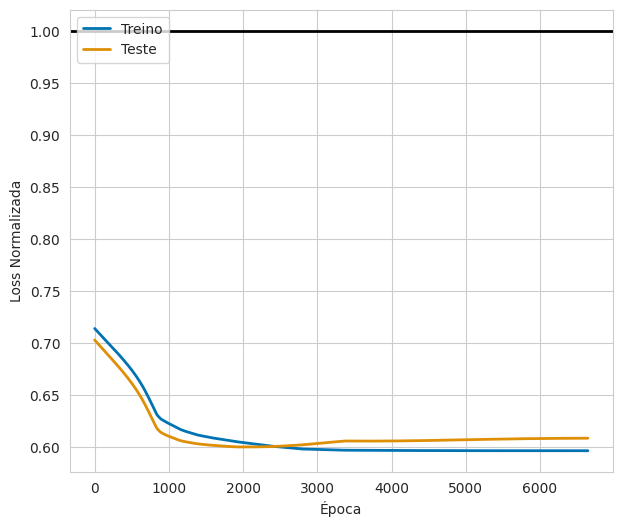

Loss Normalizada (Treino): 0.59623986
Loss Normalizada (Teste): 0.60825765


Peso      Loss   N2GLoss  Loss_Teste  N2GLoss_Teste
Sample                                                         
4.0     0.570761  0.602192  0.405040    0.615887       0.405040
11.0    0.237906  0.639855  0.737074    0.693503       0.737074
9.0     0.191333  0.614814  0.678200    0.585083       0.678200

modelos/nn_titanic_v8/df_ponderador.csv


100%|██████████| 320/320 [00:00<00:00, 424B/s]


modelos/nn_titanic_v8/nn_titanic_v8.keras


100%|██████████| 82.1k/82.1k [00:00<00:00, 290kB/s]


In [40]:
nome_modelo = 'nn_titanic_v8'
ensemble_treinamento(nome_modelo, df_conj, x, y, n_modelos = 32, tipo = 'classificacao',
                     n_epocas = 256, batch_size = 1024, delta_loss_min = 0.001, delta_loss_init = 0.01, seed = 42,
                     bucket = bucket, path_gcloud = 'modelos/',
                     df_conj_teste = df_conj_teste, x_teste = x_teste, y_teste = y_teste)

In [41]:
modelo = tf.keras.models.load_model(f'{nome_modelo}/{nome_modelo}.keras')
modelo.predict(x).shape

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step


(591, 2)

In [42]:
func_loss = tf.keras.losses.CategoricalCrossentropy()
y_ref = y.mean(axis = 0)
loss_ref = func_loss(y, np.stack([y_ref]*y.shape[0], axis = 0)).numpy()
loss_treino = func_loss(y, modelo.predict(x)).numpy()
loss_treino_norm = loss_treino/loss_ref
print('Loss Normalizada (Treino): ' + str(loss_treino_norm))

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Loss Normalizada (Treino): 0.5962399


# Loop de treinamento: regressão

ponderador
Epoch 5247: early stopping
Restoring model weights from the end of the best epoch: 5183.


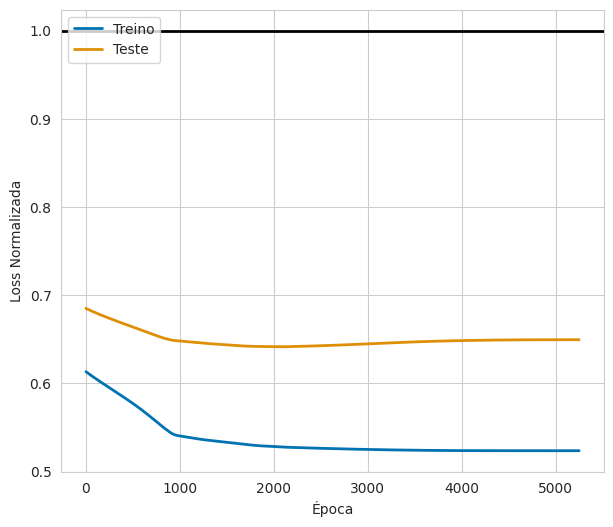

Loss Normalizada (Treino): 0.5237367
Loss Normalizada (Teste): 0.64963776


Peso      Loss    N2GLoss  Loss_Teste  N2GLoss_Teste
Sample                                                          
10.0    0.537570  0.535576   1.205971    0.680143       1.205971
23.0    0.152108  0.593856   1.342266    0.704978       1.342266
4.0     0.117329  0.569973   0.680244    0.691403       0.680244
8.0     0.112783  0.574204   0.546379    0.679189       0.546379
0.0     0.067763  0.605809   1.987489    0.657107       1.987489
7.0     0.010731  0.669812   9.451156    0.819045       9.451156
29.0    0.001715  0.850215  13.715478    0.900548      13.715478

modelos/nn_titanic2_v6/df_ponderador.csv


100%|██████████| 682/682 [00:00<00:00, 3.90kB/s]


modelos/nn_titanic2_v6/nn_titanic2_v6.keras


100%|██████████| 181k/181k [00:00<00:00, 380kB/s]


In [26]:
nome_modelo = 'nn_titanic2_v6'
ensemble_treinamento(nome_modelo, df_conj, x[:, 1:], x[:, 0], n_modelos = 32, tipo = 'regressao',
                     n_epocas = 256, batch_size = 1024, delta_loss_min = 0.001, delta_loss_init = 0.01, seed = 42,
                     bucket = bucket, path_gcloud = 'modelos/',
                     df_conj_teste = df_conj_teste, x_teste = x_teste[:, 1:], y_teste = x_teste[:, 0])

In [27]:
modelo = tf.keras.models.load_model(f'{nome_modelo}/{nome_modelo}.keras')
modelo.predict(x[:, 1:]).shape

19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step


(591, 1)

In [28]:
func_loss = tf.keras.losses.MeanSquaredError()
y_ref = x[:, 0].mean()
loss_ref = func_loss(x[:, 0], np.repeat(y_ref, x[:, 0].shape[0])).numpy()
loss_treino = func_loss(x[:, 0], modelo.predict(x[:, 1:])).numpy()
loss_treino_norm = loss_treino/loss_ref
print('Loss Normalizada (Treino): ' + str(loss_treino_norm))

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Loss Normalizada (Treino): 0.5237367


#Avaliação da métrica do desafio do Kaggle (Acurácia)

In [44]:
nome_modelo = 'nn_titanic_v8'
modelo_ref = tf.keras.models.load_model(f'{nome_modelo}/{nome_modelo}.keras')

In [45]:
df_pred = df_id.copy()
df_pred[['Prob_0', 'Prob_1']] = modelo_ref.predict(x)
df_pred['Pred_Survived'] = (df_pred['Prob_1'] >= 0.5).astype(int)
df_pred = pd.merge(df_pred, df[['PassengerId', 'Survived_1']], how = 'left', on = 'PassengerId')

df_pred_teste = df_id_teste.copy()
df_pred_teste[['Prob_0', 'Prob_1']] = modelo_ref.predict(x_teste)
df_pred_teste['Pred_Survived'] = (df_pred_teste['Prob_1'] >= 0.5).astype(int)
df_pred_teste = pd.merge(df_pred_teste, df_teste[['PassengerId', 'Survived_1']], how = 'left', on = 'PassengerId')

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


In [46]:
(df_pred['Pred_Survived'] == df_pred['Survived_1']).mean()

0.8341793570219966

In [47]:
(df_pred_teste['Pred_Survived'] == df_pred_teste['Survived_1']).mean()

0.84

# Predição teste

In [48]:
df_teste_real = pd.read_csv('test.csv', dtype = {'Survived': str, 'Pclass': str})

df_teste_real['Titulo'] = df_teste_real['Name'].apply(lambda x: x.split(',')[1].split('.')[0].strip())
df_teste_real['Tem_Age'] = (~df_teste_real['Age'].isna()).astype(int)

for c, lista_v in dict_ohe.items():
    for v in lista_v:
        df_teste_real[f'{c}_{v}'] = (df_teste_real[c] == v).astype(int)
    df_teste_real = df_teste_real.drop(c, axis = 1)

features = [
    'Age'
    ,'SibSp'
    ,'Parch'
    ,'Fare'
    ,'Tem_Age'
    ,'Pclass_3'
    ,'Pclass_1'
    ,'Pclass_2'
    ,'Sex_male'
    ,'Sex_female'
    ,'Titulo_Mr'
    ,'Titulo_Miss'
    ,'Titulo_Mrs'
    ,'Titulo_Master'
    ,'Embarked_S'
    ,'Embarked_C'
    ,'Embarked_Q']

df_id_teste_real = df_teste_real[['PassengerId']].copy()

x_teste_real = (df_teste_real[features].values - medias)/desvios
x_teste_real[np.where(np.isnan(x_teste_real))] = 0

df_pred_teste_real = df_id_teste_real.copy()
df_pred_teste_real[['Prob_0', 'Prob_1']] = modelo_ref.predict(x_teste_real)
df_pred_teste_real['Pred_Survived'] = (df_pred_teste_real['Prob_1'] >= 0.5).astype(int)

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


In [49]:
df_sumissao = df_pred_teste_real[['PassengerId', 'Pred_Survived']].rename({'Pred_Survived': 'Survived'}, axis = 1)
df_sumissao.to_csv('submissao.csv', index = False)